# Name That LLM â€” first submission

A reproducible CPU baseline: **word + character TF-IDF â†’ class-balanced linear SVM**.
No downloads, API calls, external datasets, or GPU are needed. Run cells in order.

## Competition requirements checked on 30 October 2026

The [official overview](https://www.kaggle.com/competitions/name-that-llm/overview/citation)
specifies balanced accuracy (mean recall across 18 models), an offline notebook,
a maximum nine-hour CPU/GPU runtime, and output named `submission.parquet`.
Output has exactly `id` and `model`, one valid model name per test ID.
Interactive test data has one example; scoring reruns this code on the hidden test.
Never hardcode the example's size or predictions.

**Access limitation:** the [full Rules page](https://www.kaggle.com/competitions/name-that-llm/rules)
was blocked by reCAPTCHA during preparation. The [Data page](https://www.kaggle.com/competitions/name-that-llm/data)
did not expose the file contents. This is not a claim that the complete legal rules were verified.
Read and accept them in your Kaggle account before submitting. The notebook uses only
competition training data and checks its expected schema at runtime.
No real-data score is claimed; preparation checks used synthetic fixtures.

## 1. Settings and dependencies

Kaggle's Python environment normally includes these libraries. Keep Internet **off**
and choose **CPU / no accelerator**. There are no installation cells.
Locally, install `numpy pandas scipy scikit-learn pyarrow matplotlib ipython` first.
Set `DATA_DIR` to the directory containing your authorized competition files.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np  # Import NumPy as np for numerical arrays and calculations.
import pandas as pd  # Import pandas as pd for table operations and reading/writing data files.

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os  # Import Python's os module for filesystem operations.
for dirname, _, filenames in os.walk('/kaggle/input'):  # os.walk() yields each directory path, its subdirectories (ignored as _), and filenames beneath /kaggle/input.
    for filename in filenames:  # Loop through the filenames in the current directory.
        print(os.path.join(dirname, filename))  # os.path.join() builds each file's full path; print() displays it.

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub  # Import Kaggle's resource client; this import alone does not download anything.
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/fig4_round2.png
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/removed_rows.csv
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/v10_append_log.csv
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/sources.csv
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/removal_summary.csv
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/style_gap.csv
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/fig1_clean_vs_raw.png
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/dataq_results.csv
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/fig3_style_gap.png
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/ntl_open_pool.parquet
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/per_model.csv
/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/fig2_label_gain.png
/kaggle/input/competitions/name-that-llm/sample_submiss

In [2]:
from pathlib import Path  # Import Path to construct filesystem paths and check, create, or write files and directories.
import gc  # Import gc to request garbage collection after each validation model is deleted.
import importlib.util  # Import importlib.util to check whether the optional Parquet dependency is available.
import json  # Import json to serialize experiment settings and scores as JSON text.
import time  # Import time to measure elapsed training and prediction time.
import warnings  # Import warnings for Python warning handling; this notebook does not use it later.

import numpy as np  # Import NumPy as np for arrays, numeric summaries, and random-seed control.
import pandas as pd  # Import pandas as pd for CSV/Parquet input, data validation, and result tables.
import matplotlib.pyplot as plt  # Import Matplotlib's pyplot as plt to create and display the confusion-matrix plot.
import sklearn  # Import scikit-learn so its installed version can be printed and recorded.
from IPython.display import display  # Import display() to render tables in the notebook output.
from sklearn.feature_extraction.text import TfidfVectorizer  # Import TfidfVectorizer to turn text into sparse, weighted word or character feature matrices.
from sklearn.pipeline import FeatureUnion, Pipeline  # Import FeatureUnion to combine feature branches and Pipeline to chain features with the classifier.
from sklearn.svm import LinearSVC  # Import LinearSVC, a linear support-vector classifier for predicting model labels.
from sklearn.model_selection import GroupKFold  # Import GroupKFold to split validation folds while keeping shared prompt IDs together.
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix  # Import functions for balanced accuracy, per-class metrics, and confusion-matrix counts or fractions.

SEED = 42  # Set the random seed used by NumPy and the classifier for reproducibility.
N_SPLITS = 5  # Choose five prompt-group validation folds.
RUN_CV = True  # Enable cross-validation; setting False skips the validation section.
C = 1.0  # Set the SVM regularization parameter; larger C penalizes training mistakes more strongly.
BATCH_SIZE = 512  # Limit each prediction batch to 512 test passages to control inference memory.
DATA_DIR = Path('/kaggle/input/competitions/name-that-llm')  # Path() represents the expected Kaggle competition-data directory.
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()  # Path.exists() checks for Kaggle's working directory; otherwise Path.cwd() selects the current directory.
TEXT_COLUMN = None  # Leave the text-column name unset so the loading cell can detect text or text_snippet.

VALID_LABELS = [  # Begin the explicit list of permitted prediction labels.
    'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra',  # Add five GPT model-name strings to the permitted-label list.
    'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash',  # Add four Gemini model-name strings to the permitted-label list.
    'claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5',  # Add four Claude model-name strings to the permitted-label list.
    'claude-sonnet-5', 'qwen3.8-max', 'glm-5.3', 'glm-5.3-flash', 'kimi-k3',  # Add the remaining Claude, Qwen, GLM, and Kimi model-name strings.
]  # Finish the permitted-label list.
assert len(VALID_LABELS) == len(set(VALID_LABELS)) == 18  # len() counts labels; set() removes duplicates; assert requires exactly 18 distinct labels.
np.random.seed(SEED)  # np.random.seed() initializes NumPy's global random-number generator with SEED.
print(f'pandas={pd.__version__}, scikit-learn={sklearn.__version__}')  # print() displays pandas and scikit-learn version attributes using an f-string.

pandas=2.3.3, scikit-learn=1.6.1


## 2. Read and validate the data

Expected files: `train.csv` (`id`, `prompt_id`, `text`, `model`) and
`test.csv` (`id`, `text`); `sample_submission.parquet` is an optional format reference.
These input column names are checked rather than silently guessed. `text_snippet`
is also supported. CSV parsing handles quoted commas and newlines in passages.
IDs stay strings, including leading zeros. We retain punctuation, Unicode and case:
these may carry authorship information. Neither IDs nor prompt IDs are model inputs.

In [3]:
# Find the file automatically
files = list(Path("/kaggle/input").rglob("ntl_open_pool.parquet"))

print("Files found:", files)

# Load the dataset
pool = pd.read_parquet(files[0])

print(len(pool))
print(pool.model.value_counts())

Files found: [PosixPath('/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/ntl_open_pool.parquet')]
198507
model
gemini-3.8-flash          21070
gemini-3.6-flash          16794
gpt-5.6-luna              15265
gemini-3.7-flash          13622
glm-5.3-flash             13470
gpt-5.6-terra             13445
gpt-5.6-sol               12739
glm-5.3                   12185
gpt-5.5                   11328
gpt-6-astra                9805
kimi-k3                    9489
gemini-3.1-pro-preview     9286
claude-fable-5             9098
claude-sonnet-5            7850
claude-opus-4-8            6955
claude-opus-4-6            6181
claude-opus-5              5649
qwen3.8-max                4276
Name: count, dtype: int64


In [4]:
# Some Kaggle notebooks mount competition data at the older, shorter path.
if not (DATA_DIR / 'train.csv').is_file():  # Path.is_file() checks whether train.csv exists at DATA_DIR; enter this block if it does not.
    alternate = Path('/kaggle/input/name-that-llm')  # Path() represents the alternate Kaggle input directory.
    if DATA_DIR == Path('/kaggle/input/competitions/name-that-llm') and (alternate / 'train.csv').is_file():  # Check that the default path was selected and that the alternate train.csv exists before switching.
        DATA_DIR = alternate  # Use the alternate directory for subsequent data loading.

for filename in ['train.csv', 'test.csv']:  # Loop over the two required CSV filenames.
    if not (DATA_DIR / filename).is_file():  # Join DATA_DIR with each filename and use is_file() to detect a missing input file.
        raise FileNotFoundError(f'{DATA_DIR / filename}: attach the competition data or change DATA_DIR.')  # Raise FileNotFoundError with the missing path and instructions for supplying the data.

# keep_default_na=False preserves literal strings such as "NA" and "null".
train = pd.read_csv(DATA_DIR / 'train.csv', dtype=str, keep_default_na=False)  # pd.read_csv() loads training data as strings; keep_default_na=False preserves literals such as NA.
test = pd.read_csv(DATA_DIR / 'test.csv', dtype=str, keep_default_na=False)  # pd.read_csv() loads test data with the same string and missing-value settings.

# Match the pool to the train.csv schema before adding its rows.
pool_aligned = pool.copy()
if 'prompt_id' in train.columns and 'prompt_id' not in pool_aligned.columns and 'prompt_group' in pool_aligned.columns:
    pool_aligned = pool_aligned.rename(columns={'prompt_group': 'prompt_id'})
missing_pool_columns = train.columns.difference(pool_aligned.columns).tolist()
extra_pool_columns = pool_aligned.columns.difference(train.columns).tolist()
print('Pool columns missing from train schema:', missing_pool_columns)
print('Pool columns excluded from training:', extra_pool_columns)
if missing_pool_columns:
    raise ValueError(f'Pool is missing training columns: {missing_pool_columns}')
pool_aligned = pool_aligned.loc[:, train.columns]
train = pd.concat([train, pool_aligned], ignore_index=True)
print('Train:', train.shape, train.columns.tolist())  # print() shows the training table's shape; columns.tolist() converts its column names to a list.
print('Test: ', test.shape, test.columns.tolist())  # print() shows the test table's shape and column-name list.

if TEXT_COLUMN is None:  # Detect the text column only when TEXT_COLUMN has not been set explicitly.
    candidates = [c for c in ['text', 'text_snippet'] if c in train and c in test]  # Build a list of supported text-column names present in both DataFrames.
    if len(candidates) != 1:  # len() checks that exactly one shared candidate was found.
        raise ValueError(f'Set TEXT_COLUMN explicitly. Shared text candidates: {candidates}')  # Raise ValueError with the detected candidates if the text-column choice is ambiguous or missing.
    TEXT_COLUMN = candidates[0]  # Select the only shared text-column candidate.

for name, frame, required in [  # Begin looping over each dataset, its display name, and its required column-name set.
    ('train', train, {'id', 'prompt_id', TEXT_COLUMN, 'model'}),  # Specify the training DataFrame and the four columns it must contain.
    ('test', test, {'id', TEXT_COLUMN}),  # Specify the test DataFrame and its two required columns.
]:  # Finish the dataset specifications and begin the validation-loop body.
    missing = required - set(frame.columns)  # set() collects existing column names; set subtraction finds required columns that are absent.
    if missing:  # Enter the error branch if the missing-column set is nonempty.
        raise ValueError(f'{name} is missing {sorted(missing)}; inspect the attached files.')  # sorted() orders the missing column names; raise ValueError reports the invalid dataset schema.
    assert len(frame) > 0, f'{name} is empty'  # len() counts rows; assert requires a nonempty DataFrame and reports its name on failure.
    assert not frame[list(required)].isna().any().any(), f'Null field in {name}'  # list() selects required columns; isna() marks nulls; the two any() calls detect a null in any column or row.
    assert frame['id'].str.strip().ne('').all(), f'Empty ID in {name}'  # str.strip() trims IDs for this check; ne('') tests nonempty strings; all() requires every ID to pass.
    assert frame['id'].is_unique, f'Duplicate IDs in {name}'  # is_unique checks that no ID is repeated; assert stops execution if duplicates exist.
    assert frame[TEXT_COLUMN].str.strip().ne('').all(), f'Empty passage in {name}'  # str.strip(), ne(''), and all() check that every text passage contains a non-whitespace character.

assert train['prompt_id'].str.strip().ne('').all(), 'Missing training prompt IDs'  # str.strip(), ne(''), and all() require a nonblank prompt ID in every training row.
assert set(train['model']) == set(VALID_LABELS), 'Unexpected or missing training labels; recheck the official label list.'  # set() compares observed and permitted model names; assert rejects missing or unexpected labels.
assert importlib.util.find_spec('pyarrow') is not None, 'Parquet needs pyarrow; use Kaggle or install it locally before running.'  # importlib.util.find_spec() checks whether pyarrow can be located; assert reports if Parquet support is absent.

X = train[TEXT_COLUMN].reset_index(drop=True)  # Select training passages; reset_index(drop=True) creates consecutive row indices without keeping the old index.
y = train['model'].reset_index(drop=True)  # Select target model labels and reset their indices to align with X.
groups = train['prompt_id'].reset_index(drop=True)  # Select prompt IDs as validation groups and reset their indices to align with X and y.
display(train[['id', 'prompt_id', 'model']].head())  # head() selects the first five rows of these metadata columns; display() renders the resulting table.
display(y.value_counts().reindex(VALID_LABELS).rename('training_rows').to_frame())  # value_counts() counts labels; reindex() orders them; rename() names the Series; to_frame() and display() show a table.
print('Unique prompts:', groups.nunique())  # nunique() counts distinct prompt IDs; print() displays the result.
print('Passage lengths in characters:')  # print() introduces the following passage-length summary.
display(X.str.len().describe().to_frame('characters'))  # str.len() measures each passage; describe() summarizes lengths; to_frame() names the column; display() shows it.
print('Repeated training passages:', int(X.duplicated().sum()))  # duplicated() flags passages repeated after their first occurrence; sum() counts them; int() and print() display the count.

Pool columns missing from train schema: []
Pool columns excluded from training: ['also_in', 'flag_gemini37_routing_risk', 'flag_kb_proxy', 'flag_near_train_prompt', 'flag_train_prompt_regen', 'lab', 'max_cos_train', 'max_sim_train_prompt', 'n_sources', 'n_words', 'origin_hint', 'source_dataset', 'source_file', 'source_license', 'style_score']
Train: (201206, 4) ['id', 'prompt_id', 'text', 'model']
Test:  (3, 2) ['id', 'text']


,id,prompt_id,model
0,0018b3765972,p081,qwen3.8-max
1,0041ac86ee93,p073,claude-sonnet-5
2,005a19083eae,p120,gemini-3.6-flash
3,009319596f10,p073,gpt-5.6-terra
4,00d3e8c92596,p097,glm-5.3-flash


,training_rows
model,
gpt-5.5,11478
gpt-5.6-luna,15415
gpt-5.6-sol,12889
gpt-5.6-terra,13595
gpt-6-astra,9955
gemini-3.1-pro-preview,9436
gemini-3.6-flash,16944
gemini-3.7-flash,13772
gemini-3.8-flash,21220


Unique prompts: 44751
Passage lengths in characters:


,characters
count,201206.000000
mean,736.979315
std,371.868446
min,187.000000
25%,423.000000
50%,648.000000
75%,986.000000
max,2136.000000


Repeated training passages: 0


## 3. Model

Words and short phrases capture wording preferences. Character sequences capture
spelling, punctuation, typography and fragments across word boundaries. We keep
stop words because function words can reveal style. Both branches remain sparse.
Feature caps bound memory; the character branch receives slightly more weight.
These are starting choices, not tuned or measured performance claims.

`class_weight='balanced'` increases the penalty for mistakes on rarer training
classes, a reasonable starting point for mean per-class recall. SVM margins are
decision scores, not probabilities; we need only the highest-scoring model label.

In [5]:
def make_model():  # Define make_model(), which creates a new, unfitted text-classification pipeline on every call.
    # A fresh pipeline per fold prevents vocabulary/IDF leakage from validation.
    features = FeatureUnion([  # FeatureUnion() will fit two text vectorizers and concatenate their sparse feature columns.
        ('word', TfidfVectorizer(  # Name the first branch word and construct its TfidfVectorizer.
            analyzer='word', ngram_range=(1, 2), lowercase=False,  # Use single words and two-word phrases as features, preserving uppercase and lowercase differences.
            strip_accents=None, min_df=2, max_features=60_000,  # Preserve accents; require features in at least two training documents; retain at most 60,000 features.
            sublinear_tf=True, dtype=np.float32,  # Use 1 + log(term count) for nonzero term frequencies and store feature values as 32-bit floats.
        )),  # Finish the word vectorizer and its named branch tuple.
        ('char', TfidfVectorizer(  # Name the second branch char and construct a separate TfidfVectorizer.
            analyzer='char', ngram_range=(2, 5), lowercase=False,  # Use character sequences of lengths two through five, preserving case.
            strip_accents=None, min_df=2, max_features=120_000,  # Preserve accents; require features in at least two training documents; retain at most 120,000 features.
            sublinear_tf=True, dtype=np.float32,  # Apply logarithmic term-frequency scaling and store values as 32-bit floats for the character branch.
        )),  # Finish the character vectorizer and its named branch tuple.
    ], transformer_weights={'word': 0.7, 'char': 1.0}, n_jobs=1)  # Finish FeatureUnion; scale word features by 0.7 and character features by 1.0; run branches with one job.
    return Pipeline([  # Pipeline() connects feature extraction to classification; return gives the new pipeline to the caller.
        ('features', features),  # Add the combined vectorizers as the pipeline's features step.
        ('classifier', LinearSVC(  # Add a LinearSVC instance as the pipeline's classifier step.
            C=C, class_weight='balanced', dual=True,  # Use the configured C; balance class penalties inversely by training frequency; solve the SVM's dual problem.
            max_iter=10_000, tol=1e-4, random_state=SEED,  # Allow up to 10,000 optimizer iterations, use tolerance 0.0001, and seed the solver's randomness.
        )),  # Finish the classifier constructor and its named pipeline step.
    ])  # Finish constructing and returning the pipeline.

## 4. Validate on held-out prompts

Responses to a shared prompt must stay together: otherwise training can contain
nearby answers to the validation question. GroupKFold tests transfer to other
prompts. The TF-IDF vocabulary is learned on each training fold only.
We also reject exact repeated passages across a fold boundary; if this triggers,
merge the affected prompt groups before proceeding. Do not ignore the assertion.

Out-of-fold (OOF) predictions give each training row one prediction from a model
that did not train on its prompt. The pooled balanced accuracy is the main local
score. It is an estimate, not a guarantee of leaderboard performance.

Fold 1: balanced accuracy=0.4570; seconds=1045.0
Fold 2: balanced accuracy=0.4573; seconds=1052.6
Fold 3: balanced accuracy=0.4604; seconds=1017.7
Fold 4: balanced accuracy=0.4533; seconds=997.9
Fold 5: balanced accuracy=0.4504; seconds=1020.7
Pooled OOF balanced accuracy: 0.4546
Fold mean: 0.4557; fold SD: 0.0035
Uniform-random expected balanced accuracy: 0.0556


,precision,recall,f1-score,support
gpt-5.5,0.496292,0.577191,0.533693,11478.0
gpt-5.6-luna,0.486943,0.500811,0.493780,15415.0
gpt-5.6-sol,0.387869,0.345799,0.365628,12889.0
gpt-5.6-terra,0.423775,0.391762,0.407140,13595.0
gpt-6-astra,0.608296,0.704169,0.652731,9955.0
gemini-3.1-pro-preview,0.614401,0.702628,0.655559,9436.0
gemini-3.6-flash,0.599859,0.651086,0.624423,16944.0
gemini-3.7-flash,0.335865,0.301844,0.317947,13772.0
gemini-3.8-flash,0.511593,0.476249,0.493288,21220.0
claude-fable-5,0.266933,0.267222,0.267077,9247.0


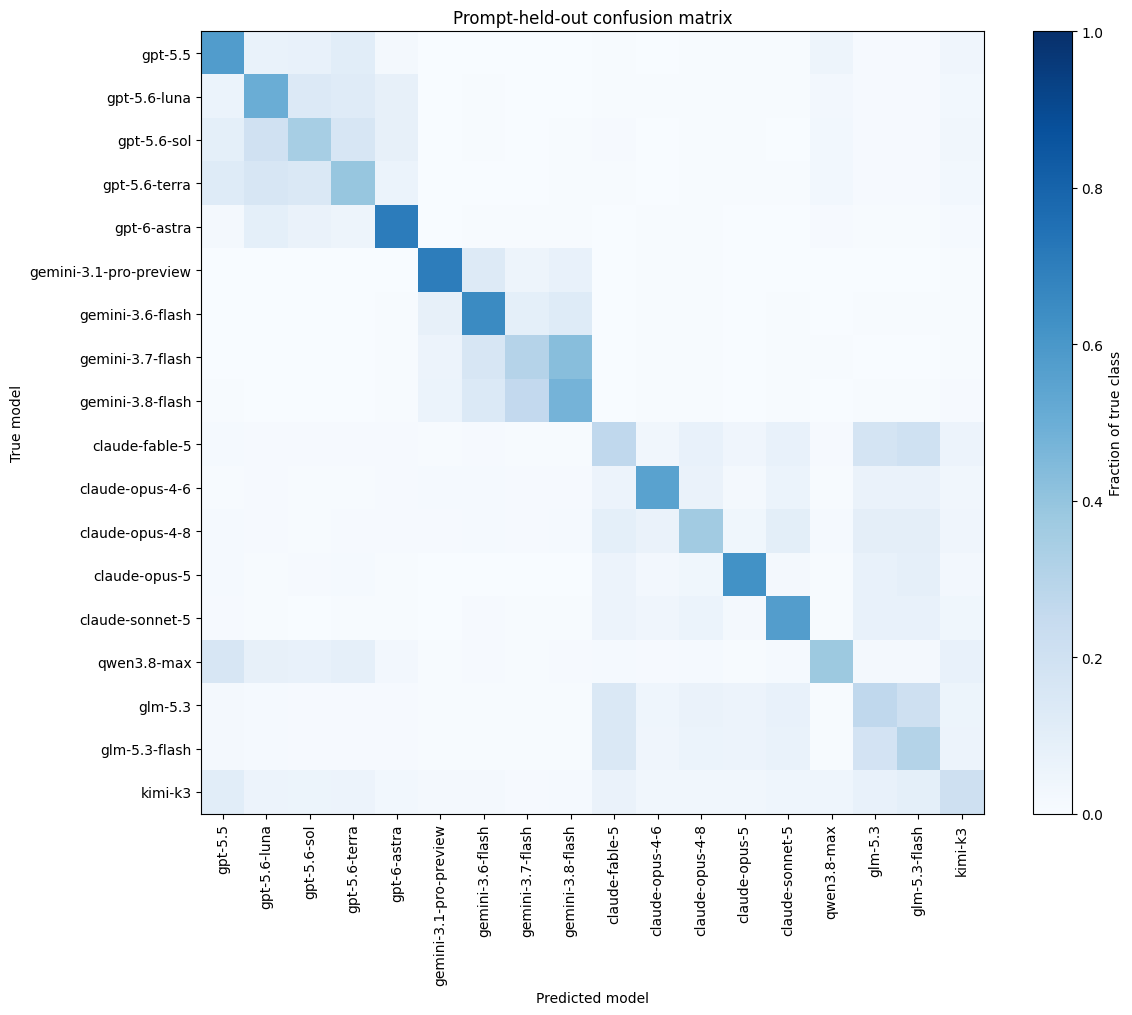

In [6]:
cv_summary = None  # Initialize the optional validation summary to None for runs that skip cross-validation.
if RUN_CV:  # Run the validation block only when RUN_CV is True.
    assert 2 <= N_SPLITS <= groups.nunique()  # nunique() counts prompt groups; assert requires between two folds and the number of distinct groups.
    splitter = GroupKFold(n_splits=N_SPLITS)  # GroupKFold() creates a splitter that keeps every prompt group within a single validation fold.
    oof = np.full(len(train), '', dtype=object)  # len() counts training rows; np.full() creates an object array of empty strings for out-of-fold predictions.
    fold_scores = []  # Create an empty list to collect each fold's balanced-accuracy score.
    for fold, (fit_idx, val_idx) in enumerate(splitter.split(X, y, groups), start=1):  # split() yields training/validation row indices; enumerate(start=1) also supplies fold numbers starting at one.
        assert set(groups.iloc[fit_idx]).isdisjoint(set(groups.iloc[val_idx]))  # iloc selects group IDs by row position; set() and isdisjoint() verify no prompt belongs to both sides.
        assert set(X.iloc[fit_idx]).isdisjoint(set(X.iloc[val_idx])), 'Duplicate text crosses prompts; merge those prompt groups.'  # iloc selects passages; set() and isdisjoint() reject exact training/validation text duplicates across prompts.
        assert set(y.iloc[fit_idx]) == set(VALID_LABELS), 'A training fold lacks a class.'  # iloc selects training labels; set() equality requires every permitted class in this training fold.
        assert set(y.iloc[val_idx]) == set(VALID_LABELS), 'A validation fold lacks a class; reduce N_SPLITS or revise groups.'  # iloc selects validation labels; set() equality requires every permitted class in this validation fold.
        start = time.perf_counter()  # time.perf_counter() records a high-resolution start time for this fold.
        fold_model = make_model()  # make_model() creates fresh vectorizers and a classifier so validation data cannot affect feature fitting.
        fold_model.fit(X.iloc[fit_idx], y.iloc[fit_idx])  # fit() learns vocabularies, IDF weights, and SVM parameters using only this fold's training rows.
        predictions = fold_model.predict(X.iloc[val_idx])  # predict() transforms the validation passages and returns their predicted model labels.
        oof[val_idx] = predictions  # Store these predictions at their original row positions in the out-of-fold array.
        score = balanced_accuracy_score(y.iloc[val_idx], predictions)  # balanced_accuracy_score() computes the mean per-class recall on this validation fold.
        fold_scores.append(float(score))  # float() converts the score to a Python number; append() adds it to the score list.
        print(f'Fold {fold}: balanced accuracy={score:.4f}; seconds={time.perf_counter() - start:.1f}')  # print() displays the fold score to four decimals and the elapsed perf_counter() time to one decimal.
        del fold_model  # Delete this fold's pipeline reference so it can release its trained model and feature data.
        gc.collect()  # gc.collect() requests collection of unreachable objects before the next fold.

    assert np.all(oof != '')  # np.all() requires every out-of-fold entry to have been filled with a prediction.
    pooled_score = balanced_accuracy_score(y, oof)  # balanced_accuracy_score() computes mean per-class recall from all out-of-fold predictions together.
    print(f'Pooled OOF balanced accuracy: {pooled_score:.4f}')  # print() displays the pooled validation score to four decimal places.
    print(f'Fold mean: {np.mean(fold_scores):.4f}; fold SD: {np.std(fold_scores):.4f}')  # np.mean() calculates the mean fold score; np.std() calculates its population standard deviation; print() shows both.
    print(f'Uniform-random expected balanced accuracy: {1 / len(VALID_LABELS):.4f}')  # len() counts classes; 1 divided by that count is the expected balanced accuracy for uniform random guesses.
    report = pd.DataFrame(classification_report(  # classification_report() creates per-class metrics; pd.DataFrame() will convert its returned dictionary to a table.
        y, oof, labels=VALID_LABELS, output_dict=True, zero_division=0,  # Compare true and out-of-fold labels in the specified order; return a dictionary and use zero for undefined metrics.
    )).T  # Finish the report table and transpose it with .T so each class occupies a row.
    display(report.loc[VALID_LABELS, ['precision', 'recall', 'f1-score', 'support']])  # loc selects permitted-label rows and four metric columns; display() renders this per-class report.
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # mkdir() creates the output directory and missing parents; exist_ok=True accepts an existing directory.
    pd.DataFrame({'id': train['id'], 'true_model': y, 'predicted_model': oof}).to_csv(  # pd.DataFrame() combines IDs, true labels, and held-out predictions; to_csv() begins writing the table.
        OUTPUT_DIR / 'oof_predictions.csv', index=False,  # Choose the CSV output path and omit the DataFrame index from the saved file.
    )  # Finish the to_csv() call.
    cv_summary = {'pooled_balanced_accuracy': float(pooled_score), 'fold_scores': fold_scores}  # Record the pooled score as a Python float and retain the individual fold scores in a dictionary.

    # Each row sums to one; the diagonal is recall for each true model.
    cm = confusion_matrix(y, oof, labels=VALID_LABELS, normalize='true')  # confusion_matrix() orders classes by VALID_LABELS and normalizes each true-class row to fractions.
    fig, ax = plt.subplots(figsize=(12, 10))  # plt.subplots() creates a figure and axes with width 12 inches and height 10 inches.
    im = ax.imshow(cm, vmin=0, vmax=1, cmap='Blues')  # imshow() draws the matrix with a blue color scale fixed between zero and one; retain its image object.
    ax.set_xticks(range(18), labels=VALID_LABELS, rotation=90)  # range(18) provides class positions; set_xticks() labels them and rotates the labels 90 degrees.
    ax.set_yticks(range(18), labels=VALID_LABELS)  # range(18) provides row positions; set_yticks() assigns the true-class labels.
    ax.set(xlabel='Predicted model', ylabel='True model', title='Prompt-held-out confusion matrix')  # ax.set() sets the horizontal label, vertical label, and plot title.
    fig.colorbar(im, ax=ax, label='Fraction of true class')  # fig.colorbar() adds a labeled legend for the matrix colors beside these axes.
    plt.tight_layout()  # plt.tight_layout() adjusts plot spacing to reduce overlap and clipping.
    plt.show()  # plt.show() displays the completed confusion-matrix figure.
else:  # Use this branch when RUN_CV is False.
    print('Cross-validation skipped; no local performance estimate.')  # print() states that validation was skipped and no local score was computed.

## 5. Refit and predict every test row

Train a fresh pipeline on all labeled data after validation. Predict independently
for each passage; do not force equal class counts or one model per inferred prompt.
The hidden test class distribution is unequal. Batching works for the interactive
example and for thousands of hidden rows.

In [7]:
start = time.perf_counter()  # time.perf_counter() records the start of full-data training and test prediction.
final_model = make_model()  # make_model() constructs a new, unfitted pipeline for the final model.
final_model.fit(X, y)  # fit() learns text features and trains the classifier on all available labeled passages.
test_predictions = np.concatenate([  # np.concatenate() will join the list of per-batch prediction arrays into one array in test-row order.
    final_model.predict(test[TEXT_COLUMN].iloc[start_row:start_row + BATCH_SIZE])  # iloc slices this batch of test passages; predict() returns the final model's labels for the batch.
    for start_row in range(0, len(test), BATCH_SIZE)  # range() generates batch starting positions from zero to len(test), stepping by BATCH_SIZE.
])  # Finish the batch list comprehension and concatenate its prediction arrays.
print(f'Refit and inference: {time.perf_counter() - start:.1f} seconds')  # time.perf_counter() minus start gives elapsed seconds; print() displays the duration to one decimal place.
display(pd.Series(test_predictions).value_counts().rename('predicted_rows').to_frame())  # pd.Series() wraps predictions; value_counts() counts labels; rename() and to_frame() prepare a table for display().

Refit and inference: 1165.9 seconds


,predicted_rows
gemini-3.6-flash,1
gpt-5.6-sol,1
gemini-3.1-pro-preview,1


## 6. Write and read back the submission

Parquet is a binary table format: a CSV renamed to `.parquet` will not work.
The interactive sample submission can confirm column names, but its example IDs
and row count must never control inference on the hidden rerun.

In [8]:
def validate_submission(frame, expected_ids):  # Define validate_submission() to check a prediction table against the expected test IDs.
    assert frame.columns.tolist() == ['id', 'model']  # columns.tolist() returns ordered column names; assert requires exactly id followed by model.
    assert len(frame) == len(expected_ids)  # len() compares row counts; assert requires one submission row per expected test ID.
    assert not frame.isna().any().any()  # isna() marks missing fields; two any() calls detect any null anywhere; assert rejects such a table.
    assert frame['id'].is_unique  # is_unique checks that each submission ID occurs only once.
    assert frame['id'].str.strip().ne('').all()  # str.strip() trims IDs for this check; ne('') and all() require every ID to be nonblank.
    assert frame['id'].tolist() == expected_ids.tolist(), 'IDs or their order changed'  # tolist() converts both ID columns to lists; assert checks identical values and row ordering.
    assert frame['model'].isin(VALID_LABELS).all(), 'Invalid model name'  # isin() marks valid model labels; all() and assert require every prediction to use a permitted name.

sample_path = DATA_DIR / 'sample_submission.parquet'  # Join DATA_DIR with the optional sample submission filename.
if sample_path.is_file():  # is_file() checks whether a sample submission is available before reading it.
    sample = pd.read_parquet(sample_path)  # pd.read_parquet() loads the sample Parquet table into a DataFrame.
    assert set(sample.columns) == {'id', 'model'}, 'Sample schema differs; recheck requirements.'  # set() compares sample column names without regard to order; assert requires exactly id and model.

submission = pd.DataFrame({'id': test['id'].to_numpy(), 'model': test_predictions})  # to_numpy() extracts test IDs in row order; pd.DataFrame() pairs them with the predicted model labels.
validate_submission(submission, test['id'])  # validate_submission() checks the in-memory table before saving it.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # mkdir() creates the output directory and any missing parents, accepting an existing directory.
submission_path = OUTPUT_DIR / 'submission.parquet'  # Build the output path for the required submission.parquet file.
submission.to_parquet(submission_path, engine='pyarrow', index=False)  # to_parquet() writes a genuine Parquet file using pyarrow and omits the DataFrame index.
saved = pd.read_parquet(submission_path, engine='pyarrow')  # pd.read_parquet() reads the written file back using pyarrow to verify the saved artifact.
validate_submission(saved, test['id'])  # validate_submission() checks the reloaded file against the original test IDs.
pd.testing.assert_frame_equal(saved, submission)  # pd.testing.assert_frame_equal() verifies that reloaded values, indices, columns, and dtypes match the original table.

# A small experiment record helps compare later changes without guessing settings.
metadata = {  # Begin a dictionary recording the experiment settings and results.
    'seed': SEED, 'C': C, 'n_splits': N_SPLITS, 'text_column': TEXT_COLUMN,  # Record the random seed, SVM regularization, fold count, and selected text-column name.
    'training_rows': len(train), 'test_rows': len(test), 'cv': cv_summary,  # len() counts training and test rows; also record the validation summary or None if skipped.
    'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,  # Record the installed pandas and scikit-learn version strings.
}  # Finish the experiment-metadata dictionary.
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')  # json.dumps(indent=2) formats metadata as JSON; Path.write_text() saves it as a UTF-8 experiment record.
print(f'Validated {len(saved):,} predictions: {submission_path}')  # len() counts saved predictions; print() displays a comma-formatted count and the submission file path.
display(saved.head())  # head() selects the first five saved predictions; display() renders them for inspection.

Validated 3 predictions: /kaggle/working/submission.parquet


,id,model
0,00353fb1c541,gemini-3.6-flash
1,005f5a9a6139,gpt-5.6-sol
2,0062a53d5487,gemini-3.1-pro-preview


## 7. Submit on Kaggle

1. Join the competition and review/accept its full rules yourself.
2. Create a competition notebook, import this `.ipynb`, and attach the competition data.
3. Select CPU, turn Internet **off**, and run all cells. Check the validation results
   and the final message confirming `submission.parquet` was read back successfully.
4. Choose **Save Version â†’ Save & Run All**. Wait for that version to finish.
5. Open its **Output** and submit `submission.parquet` to the competition. Kaggle
   will rerun the notebook with hidden test rows before returning a score.

See [Kaggle's submission documentation](https://www.kaggle.com/docs/competitions).
Creating an interactive output file alone does not submit an entry.

For a second experiment, compare character n-gram ranges or C values on the same
prompt folds. Inspect the per-model recall to find weak sibling-model distinctions.
Keep experiments small and record settings. This notebook needs no external models;
any later external data/model additions require their own licensing and rules review.